In [8]:
%pip install pygad

  Using cached pygad-3.7.0-py3-none-any.whl.metadata (18 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached pygad-3.7.0-py3-none-any.whl (218 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]

Note: you may need to restart the kernel to use updated packages.


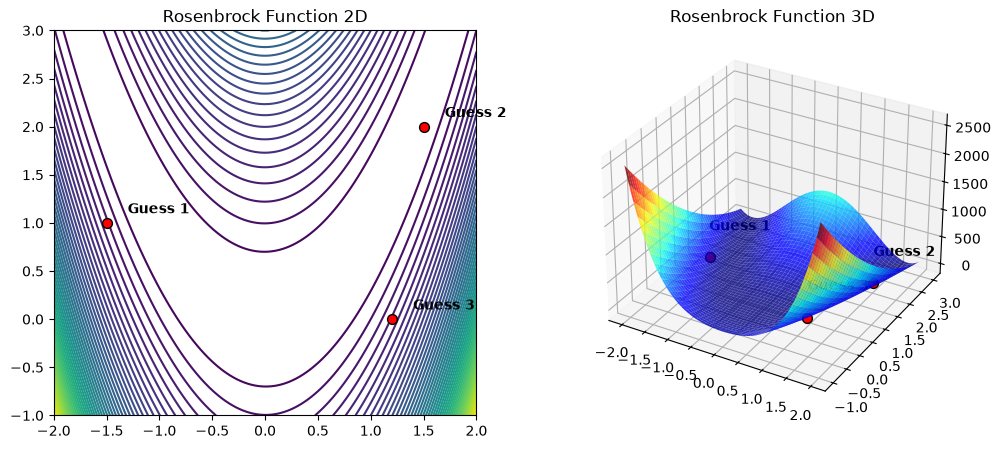

Initial guess [-1.5, 1], Result: [0.99999521 0.9999904 ], Value: 2.3007514316117746e-11, Success: True, Iterations: 27, Time: 0.0142 sec
Initial guess [1.5, 2], Result: [0.99999506 0.99999011], Value: 2.4408994262766184e-11, Success: True, Iterations: 17, Time: 0.0088 sec
Initial guess [1.2, 0], Result: [0.99999548 0.99999096], Value: 2.0416408403720154e-11, Success: True, Iterations: 27, Time: 0.0111 sec
PyGAD initial guess [-1.5, 1], Solution: [0.99858975 0.99620782], Value: rosenbrock(solution), iterations: 2000, Time: 1.8791 sec
PyGAD initial guess [1.5, 2], Solution: [1.00199571 1.00527609], Value: rosenbrock(solution), iterations: 2000, Time: 1.8190 sec
PyGAD initial guess [1.2, 0], Solution: [1.00882021 1.01800792], Value: rosenbrock(solution), iterations: 2000, Time: 1.8237 sec


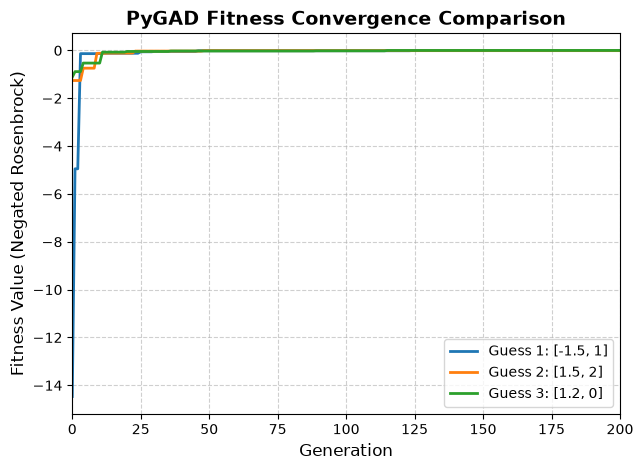

In [12]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

init_guesses = [[-1.5, 1], [1.5, 2], [1.2, 0]]

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)

for i, guess in enumerate(init_guesses):
    ax1.scatter(guess[0], guess[1], color='red', s=50, edgecolors='black', zorder=5, 
                label='Initial Guess' if i == 0 else "")
    ax1.text(guess[0] + 0.2, guess[1] + 0.1, f"Guess {i+1}", fontsize=10, weight='bold') 

ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)

for i, guess in enumerate(init_guesses):
    z_val = rosenbrock(guess) # Compute Z coordinate for the guess
    ax2.scatter(guess[0], guess[1], z_val, color='red', s=50, edgecolors='black', depthshade=False)
    ax2.text(guess[0], guess[1], z_val + 500, f"Guess {i+1}", color='black', weight='bold')


ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization

for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []

for i, guess in enumerate(init_guesses):
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: rosenbrock(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")

    fitness_history = ga_instance.best_solutions_fitness
    plt.plot(fitness_history, label=f"Guess {i+1}: {guess}", linewidth=2)
   
plt.title("PyGAD Fitness Convergence Comparison", fontsize=14, weight='bold')
plt.xlabel("Generation", fontsize=12)
plt.ylabel("Fitness Value (Negated Rosenbrock)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right") # Displays labels for each guess line
plt.tight_layout()
plt.xlim(0, 200)        # Focus only on the first 300 generations
#plt.ylim(-50, 2)        # Focus closely on the fitness values between -50 and +2
plt.show()
    #Uncomment to plot fitness:
    #ga_instance.plot_fitness()

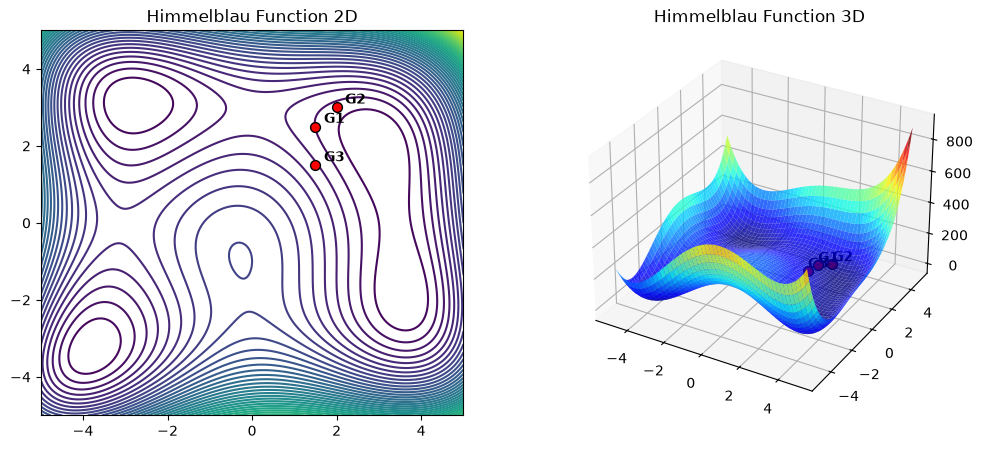

Initial guess [1.5, 2.5], Result: [3.00000001 2.00000009], Value: 1.5819660637035105e-13, Success: True, Iterations: 7, Time: 1.8303 sec
Initial guess [2, 3], Result: [2.99999999 1.99999997], Value: 2.492888014791407e-14, Success: True, Iterations: 8, Time: 1.8303 sec
Initial guess [1.5, 1.5], Result: [2.99999999 2.        ], Value: 2.4142979934273736e-15, Success: True, Iterations: 9, Time: 1.8303 sec
PyGAD initial guess [1.5, 2.5], Solution: [2.99385537 2.00338464], Value: 0.0011734338350012916, iterations: 2000, Time: 1.8303 sec
PyGAD initial guess [2, 3], Solution: [ 3.57196691 -1.84445212], Value: 0.007988556153957936, iterations: 2000, Time: 1.8303 sec
PyGAD initial guess [1.5, 1.5], Solution: [2.99357295 1.9987755 ], Value: 0.0017079254937871183, iterations: 2000, Time: 1.8303 sec


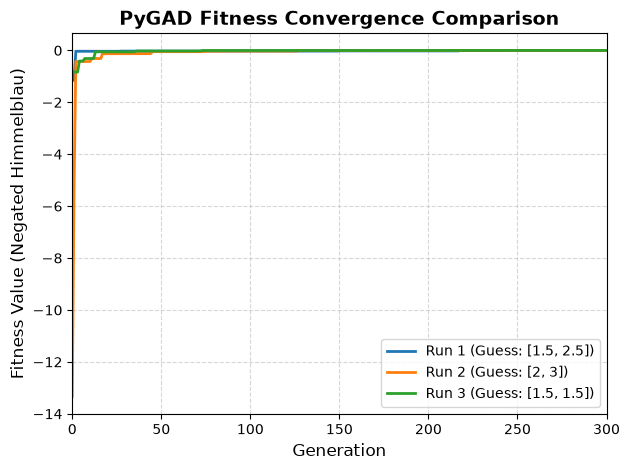

In [30]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)

# Plotting initial guesses on 2D
for i, guess in enumerate(init_guesses):
    ax1.scatter(guess[0], guess[1], color='red', s=50, edgecolors='black', zorder=5,
                label='Initial Guess' if i == 0 else "")
    ax1.text(guess[0] + 0.2, guess[1] + 0.1, f"G{i+1}", fontsize=10, weight='bold', color='black')

ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)

# Plotting initial guesses on 3D
for i, guess in enumerate(init_guesses):
    z_val = himmelblau(guess)
    ax2.scatter(guess[0], guess[1], z_val, color='red', s=50, edgecolors='black', depthshade=False)
    ax2.text(guess[0], guess[1], z_val + 20, f"G{i+1}", color='black', weight='bold')
    
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [[1.5, 2.5], [2, 3], [1.5, 1.5]]
for guess in init_guesses:
    result = minimize(himmelblau, guess, method='BFGS')
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for i, guess in enumerate(init_guesses):
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, iterations: {iters}, Time: {elapsed_time:.4f} sec") # TODO include iterations and time taken
# 2. Extract and plot the current loop's history to the shared canvas
    fitness_history = ga_instance.best_solutions_fitness
    plt.plot(fitness_history, label=f"Run {i+1} (Guess: {guess})", linewidth=2)

# 3. Finalize and style the combined chart AFTER the loop finishes
plt.title("PyGAD Fitness Convergence Comparison", fontsize=14, weight='bold')
plt.xlabel("Generation", fontsize=12)
plt.ylabel("Fitness Value (Negated Himmelblau)", fontsize=12)

# 4. Zoom in to bypass massive negative outliers at the start
plt.xlim(0, 300) 

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower right") # Displays the color key for all runs
plt.tight_layout()
plt.show() # Renders everything together on one screen
#ga_instance.plot_fitness()

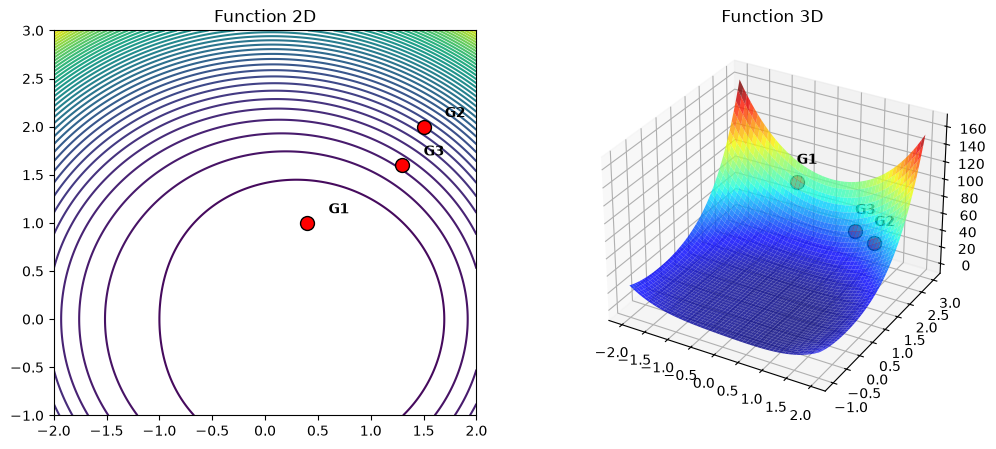

Initial guess [0.4, 1], Result: [ 9.99999964e-01 -3.66171379e-08], Value: 7.900819264927649e-15, Success: True, Iterations: 8, Time: 0.0089 sec
Initial guess [1.5, 2], Result: [9.99999959e-01 6.62851602e-08], Value: 1.259820803758452e-14, Success: True, Iterations: 11, Time: 0.0051 sec
Initial guess [1.3, 1.6], Result: [1.00000025e+00 1.89584010e-06], Value: 3.9117062674170604e-12, Success: True, Iterations: 9, Time: 0.0070 sec
PyGAD initial guess [0.4, 1], Solution: [ 9.99908032e-01 -6.28247780e-05], Value: func_1(solution), iterations: 2000, Time: 2.0065 sec
PyGAD initial guess [1.5, 2], Solution: [9.99973640e-01 2.77938993e-04], Value: func_1(solution), iterations: 2000, Time: 1.7254 sec
PyGAD initial guess [1.3, 1.6], Solution: [ 0.99942998 -0.00141088], Value: func_1(solution), iterations: 2000, Time: 1.8303 sec


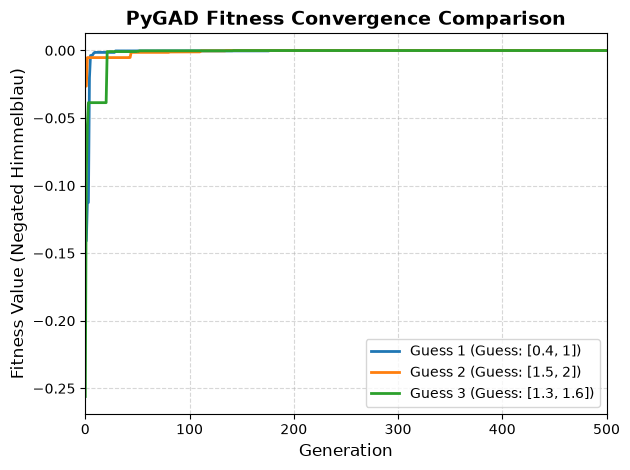

In [27]:
# Define Rosenbrock function
def func_1(x):
    return ((x[0]**2 + x[1]**2 -1)**2 + (x[0] - 1)**2 +x[1]**2)

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = func_1([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
# Plotting initial guesses on 2D
for i, guess in enumerate(init_guesses):
    ax1.scatter(guess[0], guess[1], color='red', s=100, edgecolors='black', zorder=5,
                label='Initial Guess' if i == 0 else "")
    ax1.text(guess[0] + 0.2, guess[1] + 0.1, f"G{i+1}", fontsize=10, weight='bold', color='black')
ax1.set_title("Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
# Plotting initial guesses on 3D
for i, guess in enumerate(init_guesses):
    z_val = himmelblau(guess)
    ax2.scatter(guess[0], guess[1], z_val, color='red', s=100, edgecolors='black', depthshade=False)
    ax2.text(guess[0], guess[1], z_val + 20, f"G{i+1}", color='black', weight='bold')
ax2.set_title("Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[0.4, 1], [1.5, 2], [1.3, 1.6]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(func_1, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -func_1(solution) # pygad maximizes, so negate

elapsed_time = []
for i, guess in enumerate(init_guesses):
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: func_1(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    # 2. Extract and plot the current loop's history to the shared canvas
    fitness_history = ga_instance.best_solutions_fitness
    plt.plot(fitness_history, label=f"Guess {i+1} (Guess: {guess})", linewidth=2)

# 3. Finalize and style the combined chart AFTER the loop finishes
plt.title("PyGAD Fitness Convergence Comparison", fontsize=14, weight='bold')
plt.xlabel("Generation", fontsize=12)
plt.ylabel("Fitness Value (Negated Himmelblau)", fontsize=12)

# 4. Zoom in to bypass massive negative outliers at the start
plt.xlim(0,500) 

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower right") # Displays the color key for all runs
plt.tight_layout()
plt.show() # Renders everything together on one screen
#Uncomment to plot fitness:
#   ga_instance.plot_fitness()